# Fase 1: Análise Exploratória (EDA)

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

caminho_csv = Path("../data/manutencao_preditiva.csv")
if not caminho_csv.exists():
    caminho_csv = Path("data/manutencao_preditiva.csv")

df = pd.read_csv(caminho_csv)

print(f"Dimensões do Dataset: {df.shape[0]} linhas e {df.shape[1]} colunas\n")
print("--- Tipos de Dados das Variáveis ---")
print(df.dtypes)
print("\n--- Primeiras Linhas ---")
display(df.head())
print("\n--- Resumo Estatístico Descritivo ---")
display(df.describe().T)

Dimensões do Dataset: 10000 linhas e 14 colunas

--- Tipos de Dados das Variáveis ---
udi                          int64
id_produto                     str
tipo                           str
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object

--- Primeiras Linhas ---


,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0



--- Resumo Estatístico Descritivo ---


,count,mean,std,min,25%,50%,75%,max
udi,10000.0,5000.500000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
temperatura_ar_k,9500.0,300.002158,2.001689,295.3,298.30,300.1,301.50,304.5
temperatura_processo_k,9500.0,310.000895,1.486432,305.7,308.80,310.1,311.10,313.8
velocidade_rotacao_rpm,9500.0,1539.245263,180.273589,1168.0,1423.00,1504.0,1613.00,2886.0
torque_nm,9500.0,39.974168,9.995453,3.8,33.10,40.1,46.70,76.6
desgaste_ferramenta_min,10000.0,107.951000,63.654147,0.0,53.00,108.0,162.00,253.0
falha_maquina,10000.0,0.033900,0.180981,0.0,0.00,0.0,0.00,1.0
falha_twf,10000.0,0.004600,0.067671,0.0,0.00,0.0,0.00,1.0
falha_hdf,10000.0,0.011500,0.106625,0.0,0.00,0.0,0.00,1.0
falha_pwf,10000.0,0.009500,0.097009,0.0,0.00,0.0,0.00,1.0


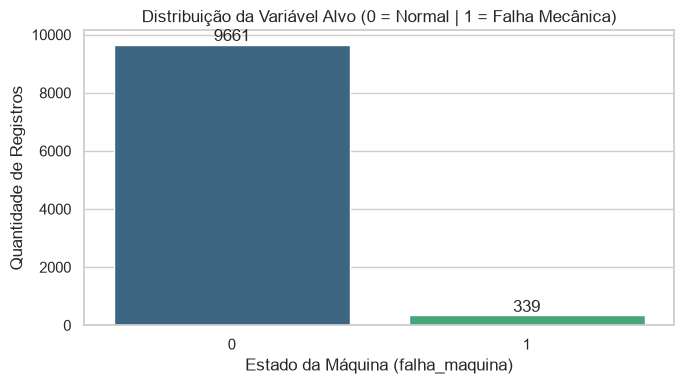

Proporção: Normal (0) = 96.61% | Falha (1) = 3.39%



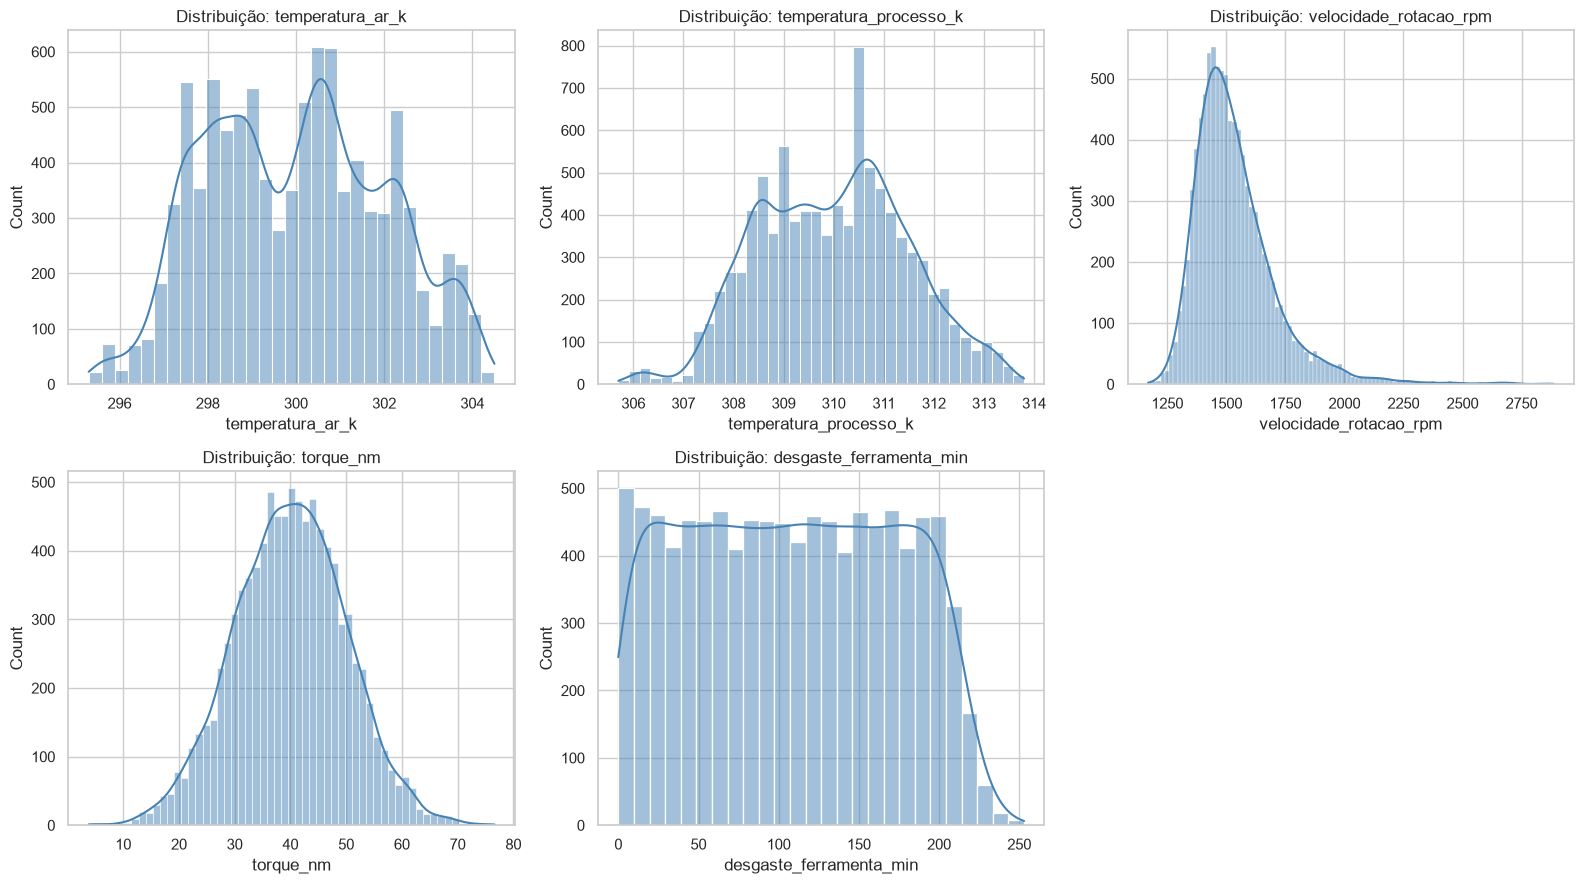

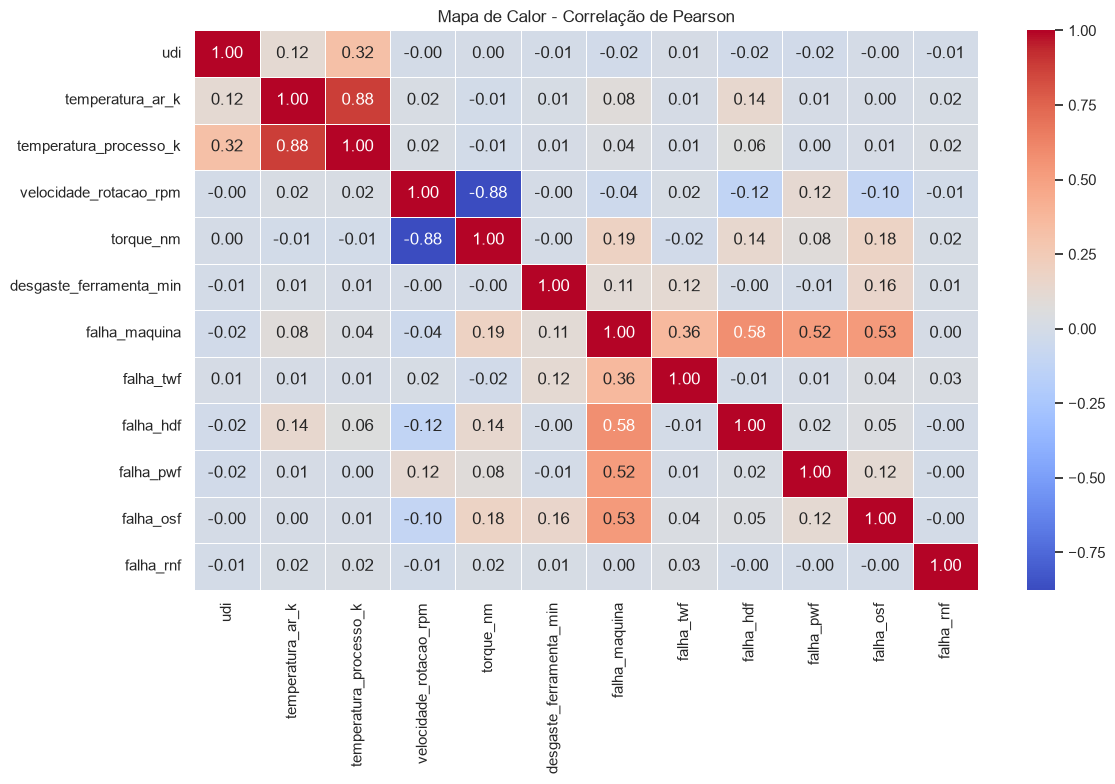

In [3]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="falha_maquina", hue="falha_maquina", palette="viridis", legend=False)
plt.title("Distribuição da Variável Alvo (0 = Normal | 1 = Falha Mecânica)")
plt.xlabel("Estado da Máquina (falha_maquina)")
plt.ylabel("Quantidade de Registros")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

proporcao = df["falha_maquina"].value_counts(normalize=True) * 100
print(f"Proporção: Normal (0) = {proporcao[0]:.2f}% | Falha (1) = {proporcao[1]:.2f}%\n")

colunas_sensores = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(colunas_sensores):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(f"Distribuição: {col}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
correlacao = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Mapa de Calor - Correlação de Pearson")
plt.tight_layout()
plt.show()

### Análise Exploratória e Direcionamento da Modelagem

1. **Dimensões e Escalas (`.describe()`):** A base possui 10.000 registros e 14 colunas. Observa-se na contagem (`count`) que as variáveis `temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm` e `torque_nm` possuem menos de 10.000 registros válidos, indicando a presença de valores ausentes (`NaN`) que precisarão de imputação na Fase 2. Além disso, as variáveis operam em escalas muito distintas (`velocidade_rotacao_rpm` chega a `2886 RPM`, enquanto `temperatura_ar_k` varia em torno de `300 K`), o que exigirá padronização (`StandardScaler`) para algoritmos baseados em distância como o KNN.
2. **Desbalanceamento Severo (Gráfico 1):** A variável alvo `falha_maquina` é fortemente desbalanceada, com aproximadamente **96,61%** de operação normal (`0`) e apenas **3,39%** de falhas (`1`). Treinar os classificadores diretamente nessa proporção enviesaria o modelo para a classe majoritária, tornando indispensável a divisão estratificada (`stratify=y`) e o balanceamento (SMOTE) nos dados de treino.
3. **Distribuição das Variáveis (Gráfico 2):** As temperaturas e o torque apresentam comportamento próximo à distribuição normal, porém `velocidade_rotacao_rpm` exibe assimetria positiva (cauda longa à direita), indicando potenciais *outliers* que orientam o uso da **mediana** na etapa de imputação.
4. **Correlações e Prevenção de *Data Leakage* (Gráfico 3):** Há forte correlação positiva entre `temperatura_ar_k` e `temperatura_processo_k` (`0.88`) e forte correlação negativa entre `velocidade_rotacao_rpm` e `torque_nm` (`-0.88`), fundamentando a criação de uma variável combinada de potência física na Fase 3. Conforme as Anotações do Departamento de Engenharia, as colunas `udi` e `id_produto` (identificadores) e as colunas `falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf` e `falha_rnf` (causas específicas registradas após a falha) não serão usadas como preditoras (`X`) para evitar vazamento de dados (*Data Leakage*).